# GIAI ĐOẠN 05 - TUẦN 2: THỰC NGHIỆM 2.2 - LỊCH TRÌNH HỌC COSINE DECAY WARMUP, SWA VÀ TRỌNG SỐ LỚP CHO TỪ KHÓ
## MÔ HÌNH INCEPTION 1D-CNN + BI-GRU + TEMPORAL ATTENTION VỚI LỊCH HỌC NÂNG CAO VÀ CLASS WEIGHTING
### BỘ ĐẶC TRƯNG ĐỘNG HỌC 450D (T=64) TRÊN TẬP DỮ LIỆU VSL400 (FRONT-VIEW CHÍNH DIỆN)

---

**Mục tiêu thực nghiệm:**
1. Kế thừa kiến trúc **Inception 1D-CNN + Bi-GRU + MLP Temporal Attention** (795,536 tham số) đã chứng minh ưu việt vượt ngưỡng 80% từ Thực nghiệm 2.1.
2. Tích hợp lịch trình tốc độ học **Cosine Decay with Warmup** (5 epochs khởi động từ $10^{-4}$ lên $10^{-3}$, suy giảm cosin về $10^{-6}$ qua 100 epochs) giúp tối ưu hóa bề mặt tham số và tránh kẹt tại các cực tiểu địa phương sắc nhọn.
3. Áp dụng kỹ thuật trung bình trọng số ngẫu nhiên **Stochastic Weight Averaging (SWA)** tích lũy trên các epochs cuối ($epoch \ge 70$) nhằm đưa mô hình vào cực tiểu phẳng (flat minima), gia tăng năng lực tổng quát hóa trên dữ liệu thực tế.
4. Dựa trên phân tích ma trận nhầm lẫn (`reports/hard_glosses_analysis.json`), áp dụng **Class Weighting thích nghi** cho nhóm 25 từ vựng khó nhất (Hard Glosses - độ chính xác $< 40\%$) với trọng số bù đắp $1.8\times$ nhằm kéo đồng đều phân phối nhận diện.
5. Đánh giá và đối chiếu hiệu năng giữa mô hình tốt nhất (Best Checkpoint) và mô hình trung bình SWA trên tập kiểm định và tập kiểm thử độc lập người ký (Unseen Signers Test P24–P26).

---
## 1. Thiết Lập Môi Trường & Siêu Tham Số Huấn Luyện - Cấu hình & Siêu tham số


In [1]:
import os
import sys
import json
import time
import random
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, accuracy_score

import tensorflow as tf
import keras
from keras import layers

# Đảm bảo tính tái lập kết quả thực nghiệm (Reproducibility)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Thiết lập đường dẫn thư mục dự án
def detect_project_root() -> Path:
    cur = Path.cwd()
    for p in [cur, cur.parent, cur.parent.parent]:
        if (p / "data" / "processed").exists():
            return p.resolve()
    return cur.resolve()

PROJECT_ROOT = detect_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = DATA_DIR / "splits"
CACHE_DIR = DATA_DIR / "cache"
CHECKPOINTS_DIR = PROJECT_ROOT / "experiments" / "checkpoints"
LOGS_DIR = PROJECT_ROOT / "experiments" / "logs"
RESULTS_DIR = PROJECT_ROOT / "experiments" / "results"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for d in [CACHE_DIR, CHECKPOINTS_DIR, LOGS_DIR, RESULTS_DIR, REPORTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Siêu tham số chuẩn hóa toàn cục
TARGET_FRAMES = 64
BATCH_SIZE = 64
NUM_CLASSES = 400
FEATURE_DIM = 450

print(f"Thư mục gốc dự án  : {PROJECT_ROOT}")
print(f"TensorFlow / Keras  : {tf.__version__} / {keras.__version__}")
print(f"Cấu hình huấn luyện : T={TARGET_FRAMES} frames | Batch Size={BATCH_SIZE} | Số lớp={NUM_CLASSES}")
print(f"Chiều vector đặc trưng: {FEATURE_DIM}D (225D Tọa độ không gian + 225D Đạo hàm vận tốc)")


Thư mục gốc dự án  : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System
TensorFlow / Keras  : 2.16.1 / 3.12.4
Cấu hình huấn luyện : T=64 frames | Batch Size=64 | Số lớp=400
Chiều vector đặc trưng: 450D (225D Tọa độ không gian + 225D Đạo hàm vận tốc)


---
## 2. Nạp Phân Vùng Dữ Liệu Signer-Disjoint - Kiểm tra phân vùng dữ liệu

Giao thức phân chia đảm bảo tính khách quan tuyệt đối: Tập Huấn luyện (Train), Kiểm định (Validation) và Kiểm thử (Test) không có sự trùng lặp người ký (Signer-Disjoint Protocol).


In [2]:
# 1. Nạp từ điển ánh xạ từ vựng
with open(DATA_DIR / "gloss_to_id.json", "r", encoding="utf-8") as f:
    gloss_to_id = json.load(f)
with open(DATA_DIR / "id_to_gloss.json", "r", encoding="utf-8") as f:
    id_to_gloss = {int(k): v for k, v in json.load(f).items()}

# 2. Nạp phân vùng mới (Phương án A - Part-Stratified Disjoint)
train_df = pd.read_csv(SPLITS_DIR / "train_front.csv")
val_df   = pd.read_csv(SPLITS_DIR / "val_front.csv")
test_df  = pd.read_csv(SPLITS_DIR / "test_front.csv")

for df in [train_df, val_df, test_df]:
    df["label"] = df["label"].astype(int)

train_signers = sorted(train_df["signer_id"].astype(str).str.zfill(3).unique())
val_signers   = sorted(val_df["signer_id"].astype(str).str.zfill(3).unique())
test_signers  = sorted(test_df["signer_id"].astype(str).str.zfill(3).unique())

# Kiểm tra triệt để nguy cơ rò rỉ Signer
assert set(train_signers).isdisjoint(set(val_signers)), "Lỗi rò rỉ Train-Val!"
assert set(train_signers).isdisjoint(set(test_signers)), "Lỗi rò rỉ Train-Test!"
assert set(val_signers).isdisjoint(set(test_signers)), "Lỗi rò rỉ Val-Test!"

summary_split_df = pd.DataFrame([
    {"Phân vùng": "Huấn luyện (Train)", "Số mẫu": len(train_df), "Signers": len(train_signers), "Danh sách": f"{', '.join(train_signers[:5])} ... ({len(train_signers)} signers)", "Số Gloss": train_df["gloss"].nunique()},
    {"Phân vùng": "Kiểm định (Val)",   "Số mẫu": len(val_df),   "Signers": len(val_signers),   "Danh sách": ", ".join(val_signers), "Số Gloss": val_df["gloss"].nunique()},
    {"Phân vùng": "Kiểm thử (Test)",   "Số mẫu": len(test_df),  "Signers": len(test_signers),  "Danh sách": ", ".join(test_signers), "Số Gloss": test_df["gloss"].nunique()}
])
display(summary_split_df)

,Phân vùng,Số mẫu,Signers,Danh sách,Số Gloss
0,Huấn luyện (Train),17789,20,"001, 002, 003, 004, 007 ... (20 signers)",400
1,Kiểm định (Val),3520,3,"006, 012, 026",400
2,Kiểm thử (Test),3429,3,"008, 016, 024",400


---
## 3. Nạp Bộ Dữ Liệu Đặc Trưng Chuẩn Hóa 450 Chiều - Nạp chuỗi đặc trưng

Mỗi chuỗi cử chỉ được chuẩn hóa đồng nhất:
- **Nội suy khung hình (Imputation & Resampling)**: Đồng bộ mọi chuỗi về đúng chuẩn $T=64$ khung hình qua `interp1d`.
- **Chuẩn hóa không gian bàn tay (Wrist-Centering)**: Tịnh tiến tọa độ 21 khớp xương bàn tay về gốc cổ tay ($x_0, y_0, z_0 = 0$).
- **Chuẩn hóa thân người (Chest-Centering & Scale)**: Đặt gốc tọa độ tại tâm ngực và tỷ lệ theo độ rộng hai vai.
- **Đặc trưng động học**: Ghép nối vector vận tốc tức thời $\Delta P(t) = P(t) - P(t-1)$ tạo thành không gian đặc trưng toàn diện **450 chiều**.


In [3]:
FORCE_REBUILD = False

def preprocess_sequence_450d(npy_rel_path: str, target_frames: int = TARGET_FRAMES) -> np.ndarray:
    '''Tiền xử lý chuỗi cử chỉ: Nội suy, chuẩn hóa không gian tọa độ và tính vector vận tốc động học.'''
    full_path = PROJECT_ROOT / npy_rel_path if not Path(npy_rel_path).is_absolute() else Path(npy_rel_path)
    out = np.load(full_path)
    T = len(out)
    
    # 1. Zero-frame imputation vector hóa độc lập trên 3 cụm (RH: 0-63, LH: 63-126, Pose: 126-225)
    for s, e in [(0, 63), (63, 126), (126, 225)]:
        sub = out[:, s:e]
        valid = np.where(~np.all(sub == 0, axis=1))[0]
        n_valid = len(valid)
        if n_valid == 1:
            out[:, s:e] = sub[valid[0]]
        elif 1 < n_valid < T:
            f = interp1d(valid, sub[valid], axis=0, kind="linear", bounds_error=False, fill_value=(sub[valid[0]], sub[valid[-1]]))
            out[:, s:e] = f(np.arange(T))
            
    # 2. Resample đồng nhất về target_frames (T=64)
    if T != target_frames:
        out = interp1d(np.linspace(0, 1, T), out, axis=0, kind="linear")(np.linspace(0, 1, target_frames))
    out = np.nan_to_num(out, nan=0.0)
    
    # 3. Chuẩn hóa không gian: Wrist-Centering (RH & LH) + Chest-Centering & Scale (Pose)
    for s in (0, 63):
        hand = out[:, s:s+63].reshape(target_frames, 21, 3)
        hand[:, 1:] -= hand[:, 0:1]
        out[:, s:s+63] = hand.reshape(target_frames, 63)
        
    pose = out[:, 126:225].reshape(target_frames, 33, 3)
    l_sh, r_sh = pose[:, 11:12], pose[:, 12:13]
    chest = (l_sh + r_sh) / 2.0
    width = np.linalg.norm(l_sh - r_sh, axis=-1, keepdims=True)
    width = np.where(np.isnan(width) | (width < 1e-4), 1.0, width)
    out[:, 126:225] = ((pose - chest) / width).reshape(target_frames, 99)
    
    # 4. Đạo hàm vận tốc động học [P || Delta_P] -> 450 chiều
    vel = np.zeros_like(out)
    vel[1:] = out[1:] - out[:-1]
    return np.nan_to_num(np.concatenate([out, vel], axis=-1), nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

def load_or_build_cache(df_split: pd.DataFrame, split_name: str, force: bool = False) -> tuple[np.ndarray, np.ndarray]:
    '''Tạo và nạp bộ đệm đặc trưng chuẩn hóa cho phân vùng dữ liệu.'''
    cache_X_path = CACHE_DIR / f"X_{split_name}_front_450D.npy"
    cache_y_path = CACHE_DIR / f"y_{split_name}_front.npy"
    
    if not force and cache_X_path.exists() and cache_y_path.exists():
        X_arr = np.load(cache_X_path)
        y_arr = np.load(cache_y_path)
        if len(X_arr) == len(df_split):
            print(f"[{split_name.upper():5s}] Nạp thành công: {X_arr.shape} | Nhãn: {len(y_arr)} | NaN: {np.isnan(X_arr).sum()}")
            return X_arr, y_arr

    paths = df_split["holistic_npy_path"].tolist()
    y_arr = df_split["label"].values.astype(np.int32)
    X_arr = np.zeros((len(paths), TARGET_FRAMES, FEATURE_DIM), dtype=np.float32)
    
    t0 = time.time()
    for i, p in enumerate(tqdm(paths, desc=f"[{split_name.upper():5s}] Dựng đặc trưng chuẩn", unit="mẫu")):
        X_arr[i] = preprocess_sequence_450d(p)
        
    assert np.isnan(X_arr).sum() == 0, f"Phát hiện NaN trong {split_name}!"
    np.save(cache_X_path, X_arr)
    np.save(cache_y_path, y_arr)
    elapsed = time.time() - t0
    print(f"[{split_name.upper():5s}] Đã tạo & lưu đệm trong {elapsed:.1f}s | NaN: 0")
    return X_arr, y_arr

X_train, y_train = load_or_build_cache(train_df, "train", force=FORCE_REBUILD)
X_val,   y_val   = load_or_build_cache(val_df,   "val",   force=FORCE_REBUILD)
X_test,  y_test  = load_or_build_cache(test_df,  "test",  force=FORCE_REBUILD)

print("\n" + "=" * 70)
print("TỔNG HỢP BỘ DỮ LIỆU ĐẶC TRƯNG SẴN SÀNG HUẤN LUYỆN:")
print(f"  - Tập Huấn luyện (Train) : X={X_train.shape} | y={y_train.shape}")
print(f"  - Tập Kiểm định  (Val)   : X={X_val.shape}   | y={y_val.shape}")
print(f"  - Tập Kiểm thử   (Test)  : X={X_test.shape}  | y={y_test.shape}")
print("=" * 70)


[TRAIN] Nạp thành công: (17789, 64, 450) | Nhãn: 17789 | NaN: 0
[VAL  ] Nạp thành công: (3520, 64, 450) | Nhãn: 3520 | NaN: 0
[TEST ] Nạp thành công: (3429, 64, 450) | Nhãn: 3429 | NaN: 0

TỔNG HỢP BỘ DỮ LIỆU ĐẶC TRƯNG SẴN SÀNG HUẤN LUYỆN:
  - Tập Huấn luyện (Train) : X=(17789, 64, 450) | y=(17789,)
  - Tập Kiểm định  (Val)   : X=(3520, 64, 450)   | y=(3520,)
  - Tập Kiểm thử   (Test)  : X=(3429, 64, 450)  | y=(3429,)


---
## 4. Tăng Cường Dữ Liệu Động Học & Xây Dựng Đường Ống Huấn Luyện - Tăng cường dữ liệu & Pipeline

Để nâng cao khả năng khái quát hóa và chống hiện tượng học vẹt (overfitting), các chuỗi cử chỉ trong tập huấn luyện được áp dụng các phép biến đổi hình học ngẫu nhiên theo từng batch:
1. **Co giãn không gian (Spatial Scaling)**: Dao động trong khoảng $[0.95, 1.05]$.
2. **Xoay mặt phẳng (2D Rotation)**: Góc xoay ngẫu nhiên $[-\frac{\pi}{30}, +\frac{\pi}{30}]$ quanh trục Z.
3. **Nhiễu rung tọa độ (Coordinate Jittering)**: Phân phối chuẩn $\mathcal{N}(0, 0.003)$.
4. **Cập nhật vector vận tốc $\Delta P(t)$**: Tự động tính toán lại đạo hàm vận tốc phù hợp với tọa độ vừa biến đổi.


In [4]:
# 1. Mã hóa One-Hot Encoding cho toàn bộ các tập
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=NUM_CLASSES).astype(np.float32)
y_val_onehot   = keras.utils.to_categorical(y_val,   num_classes=NUM_CLASSES).astype(np.float32)
y_test_onehot  = keras.utils.to_categorical(y_test,  num_classes=NUM_CLASSES).astype(np.float32)

AUG_SCALE_MIN = 0.95
AUG_SCALE_MAX = 1.05
AUG_ROT_ANGLE = 3.14159265 / 30.0  # ~6 độ
AUG_JITTER_STD = 0.003

@tf.function
def augment_batch_tf(x_batch, y_batch):
    '''Tăng cường dữ liệu Tensor Graph: Scaling, Rotation, Jitter và cập nhật vector vận tốc.'''
    B = tf.shape(x_batch)[0]
    coords = tf.reshape(x_batch[:, :, :225], (B, 64, 75, 3))
    
    # 1. Co giãn không gian
    scales = tf.random.uniform((B, 1, 1, 1), AUG_SCALE_MIN, AUG_SCALE_MAX, dtype=tf.float32)
    coords = coords * scales
    
    # 2. Xoay 2D mặt phẳng
    angles = tf.random.uniform((B,), -AUG_ROT_ANGLE, AUG_ROT_ANGLE, dtype=tf.float32)
    cos_a = tf.reshape(tf.cos(angles), (B, 1, 1))
    sin_a = tf.reshape(tf.sin(angles), (B, 1, 1))
    x, y, z = coords[:, :, :, 0], coords[:, :, :, 1], coords[:, :, :, 2]
    x_rot = x * cos_a - y * sin_a
    y_rot = x * sin_a + y * cos_a
    coords_rot = tf.stack([x_rot, y_rot, z], axis=-1)
    
    # 3. Nhiễu rung tọa độ
    noise = tf.random.normal(tf.shape(coords_rot), mean=0.0, stddev=AUG_JITTER_STD, dtype=tf.float32)
    coords_rot = coords_rot + noise
    coords_flat = tf.reshape(coords_rot, (B, 64, 225))
    
    # 4. Đạo hàm lại vector vận tốc động học
    v0 = tf.zeros_like(coords_flat[:, :1, :])
    v_rest = coords_flat[:, 1:, :] - coords_flat[:, :-1, :]
    vel = tf.concat([v0, v_rest], axis=1)
    
    augmented_x = tf.concat([coords_flat, vel], axis=-1)
    return augmented_x, y_batch

# 3. Khởi tạo đường ống nạp dữ liệu tf.data
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train_onehot))
    .shuffle(buffer_size=1000, seed=RANDOM_SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(augment_batch_tf, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val_onehot))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test_onehot))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Đã khởi tạo đường ống nạp dữ liệu thành công:")
print(f"  - Train Batches : {len(train_ds)} (tương đương {len(y_train)} mẫu kèm Dynamic Augmentation)")
print(f"  - Val Batches   : {len(val_ds)} (tương đương {len(y_val)} mẫu)")
print(f"  - Test Batches  : {len(test_ds)} (tương đương {len(y_test)} mẫu)")


Đã khởi tạo đường ống nạp dữ liệu thành công:
  - Train Batches : 278 (tương đương 17789 mẫu kèm Dynamic Augmentation)
  - Val Batches   : 55 (tương đương 3520 mẫu)
  - Test Batches  : 54 (tương đương 3429 mẫu)


---
## 5. Kế Thừa Kiến Trúc Inception Bi-GRU Attention từ Thực Nghiệm 2.1

Khối Multi-Scale Inception phân tách luồng đặc trưng đầu vào qua 3 nhánh tích chập độc lập:
- **Nhánh 1 ($k=1$, 96 filters)**: Nhận diện vi cử chỉ ngón tay không có độ trễ thời gian.
- **Nhánh 2 ($k=3$, 96 filters)**: Trích xuất sự biến đổi tư thế bàn tay ngắn hạn.
- **Nhánh 3 ($k=5$, 64 filters)**: Nắm bắt quỹ đạo di chuyển vĩ mô của cổ tay và cánh tay.
- **Kết nối phần dư (Residual Connection)**: Cộng luồng đặc trưng gốc qua `layers.Add` và chuẩn hóa `LayerNormalization` giúp gradient lan truyền sâu mà không bị suy giảm.
- **Mạng hồi quy hai chiều (Bidirectional GRU)**: 1 tầng Bi-GRU ($128$ đơn vị mỗi chiều).
Tổng số lượng tham số: **762,512 tham số**.


In [5]:
# ==========================================================================
# XÂY DỰNG MÔ HÌNH MULTI-SCALE INCEPTION 1D-CNN + BI-GRU + TEMPORAL ATTENTION (THỰC NGHIỆM 2.1)
# ==========================================================================

@keras.saving.register_keras_serializable(package="VSLAttention")
class TemporalMLPAttention(layers.Layer):
    '''
    Cơ chế Chú ý Thời gian dạng Cộng tính (MLP Additive Temporal Attention).
    Tính trọng số mức độ quan trọng thích nghi alpha_t cho từng khung hình t trong 64 timesteps:
        e_t = w^T * tanh(W * h_t + b)
        alpha = softmax(e)
        context = sum(alpha_t * h_t)
    '''
    def __init__(self, units: int = 128, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        hidden_dim = input_shape[-1]
        self.W = self.add_weight(
            name="attention_weight",
            shape=(hidden_dim, self.units),
            initializer="glorot_uniform",
            trainable=True,
        )
        self.b = self.add_weight(
            name="attention_bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True,
        )
        self.u = self.add_weight(
            name="attention_context_vector",
            shape=(self.units, 1),
            initializer="glorot_uniform",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs, mask=None):
        # inputs: (batch_size, time_steps, hidden_dim)
        u_t = keras.ops.tanh(keras.ops.matmul(inputs, self.W) + self.b)
        score = keras.ops.matmul(u_t, self.u)
        alpha = keras.ops.softmax(score, axis=1)
        context = keras.ops.sum(inputs * alpha, axis=1)
        return context

    def get_config(self):
        config = super().get_config()
        config.update({"units": self.units})
        return config

def build_attention_model(input_shape=(TARGET_FRAMES, FEATURE_DIM), num_classes=NUM_CLASSES) -> keras.Model:
    '''Thực nghiệm 2.1: Multi-Scale Inception 1D-CNN + 1-Layer Bi-GRU (return_sequences=True) + MLP Attention (795,536 tham số)'''
    inputs = layers.Input(shape=input_shape, name="input_landmarks_velocity")
    
    # 1. Phép chiếu đặc trưng không gian (Linear Projection)
    x = layers.Dense(256, activation="gelu", name="proj_dense")(inputs)
    x = layers.LayerNormalization(name="proj_ln")(x)
    x = layers.Dropout(0.2, name="proj_dropout")(x)
    
    # 2. Khối Multi-Scale Inception 1D-CNN kèm kết nối Residual
    b1 = layers.Conv1D(96, kernel_size=1, padding="same", activation="gelu", name="inc_b1")(x)
    b2 = layers.Conv1D(96, kernel_size=3, padding="same", activation="gelu", name="inc_b2")(x)
    b3 = layers.Conv1D(64, kernel_size=5, padding="same", activation="gelu", name="inc_b3")(x)
    concat = layers.Concatenate(name="inc_concat")([b1, b2, b3])
    concat = layers.LayerNormalization(name="inc_ln")(concat)
    x = layers.Add(name="inc_residual_add")([x, concat])
    x = layers.Dropout(0.2, name="inc_dropout")(x)
    
    # 3. Khối chuỗi thời gian Bi-GRU 1 tầng (xuất toàn bộ chuỗi 64 khung hình)
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, dropout=0.2), name="inception_bigru")(x)
    x = layers.LayerNormalization(name="gru_ln")(x)
    
    # 4. Cơ chế Chú ý Thời gian (MLP Additive Attention)
    x = TemporalMLPAttention(units=128, name="temporal_mlp_attention")(x)
    x = layers.Dropout(0.2, name="attn_dropout")(x)
    
    # 5. Tầng phân loại 400 từ vựng
    x = layers.Dense(256, activation="gelu", name="dense1")(x)
    x = layers.Dropout(0.2, name="dense1_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="gloss_predictions")(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name="vsl400_exp2_1_attention")

model = build_attention_model()
print("Khởi tạo thành công mô hình Multi-Scale Inception 1D-CNN + Bi-GRU + Temporal Attention (795,536 tham số):")
model.summary()



Khởi tạo thành công mô hình Multi-Scale Inception 1D-CNN + Bi-GRU + Temporal Attention (795,536 tham số):


Model: "vsl400_exp2_1_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_landmarks_ve… │ (None, 64, 450)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_dense (Dense)  │ (None, 64, 256)   │    115,456 │ input_landmarks_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_ln             │ (None, 64, 256)   │        512 │ proj_dense[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_dropout        │ (None, 64, 256)   │          0 │ proj_ln[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b1 (Conv1D)     │ (None, 64, 96)    │     24,672 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b2 (Conv1D)     │ (None, 64, 96)    │     73,824 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b3 (Conv1D)     │ (None, 64, 64)    │     81,984 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_concat          │ (None, 64, 256)   │          0 │ inc_b1[0][0],     │
│ (Concatenate)       │                   │            │ inc_b2[0][0],     │
│                     │                   │            │ inc_b3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_ln              │ (None, 64, 256)   │        512 │ inc_concat[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_residual_add    │ (None, 64, 256)   │          0 │ proj_dropout[0][… │
│ (Add)               │                   │            │ inc_ln[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_dropout         │ (None, 64, 256)   │          0 │ inc_residual_add… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_bigru     │ (None, 64, 256)   │    296,448 │ inc_dropout[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_ln              │ (None, 64, 256)   │        512 │ inception_bigru[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_mlp_atten… │ (None, 256)       │     33,024 │ gru_ln[0][0]      │
│ (TemporalMLPAttent… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_dropout        │ (None, 256)       │          0 │ temporal_mlp_att… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1 (Dense)      │ (None, 256)       │     65,792 │ attn_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1_dropout      │ (None, 256)       │          0 │ dense1[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gloss_predictions   │ (None, 400)       │    102,800 │ dense1_dropout[0… │
│ (Dense)             │                   │            │                 

 Total params: 795,536 (3.03 MB)

 Trainable params: 795,536 (3.03 MB)

 Non-trainable params: 0 (0.00 B)

---
## 6. Thiết Lập Lịch Trình Học Cosine Decay Warmup, SWA & Class Weighting - Thiết lập huấn luyện nâng cao

- **Hàm mất mát**: Categorical Crossentropy kết hợp Label Smoothing $\epsilon=0.08$.
- **Class Weighting**: Trọng số thích nghi bù đắp gradient $1.8\times$ cho Top 25 từ vựng khó nhận diện nhất.
- **Lịch trình học Cosine Decay with Warmup**: Khởi động 5 epochs, sau đó suy giảm hàm cosin về $10^{-6}$ qua 100 epochs.
- **Stochastic Weight Averaging (SWA)**: Tích lũy trung bình trọng số mô hình từ epoch 70 đến 100.

In [6]:
# ==========================================================================
# BIÊN DỊCH MÔ HÌNH VÀ THIẾT LẬP CALLBACKS COSINE DECAY + SWA (THỰC NGHIỆM 2.2)
# ==========================================================================
import gc

class MemoryCleanupCallback(keras.callbacks.Callback):
    '''Tự động dọn dẹp bộ nhớ tạm cuối mỗi epoch.'''
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

class CosineDecayWithWarmupCallback(keras.callbacks.Callback):
    '''Lịch trình tốc độ học Cosine Decay kết hợp 5 epochs khởi động (Warmup).'''
    def __init__(self, base_lr=1e-3, min_lr=1e-6, warmup_epochs=5, total_epochs=100, verbose=1):
        super().__init__()
        self.base_lr = base_lr
        self.min_lr = min_lr
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        self.verbose = verbose

    def on_epoch_begin(self, epoch, logs=None):
        if epoch < self.warmup_epochs:
            lr = self.base_lr * float(epoch + 1) / float(self.warmup_epochs)
        else:
            progress = float(epoch - self.warmup_epochs) / float(max(1, self.total_epochs - self.warmup_epochs))
            cosine_factor = 0.5 * (1.0 + np.cos(np.pi * progress))
            lr = self.min_lr + (self.base_lr - self.min_lr) * cosine_factor
        self.model.optimizer.learning_rate.assign(lr)
        if self.verbose and (epoch < self.warmup_epochs or (epoch + 1) % 10 == 0 or epoch >= 70):
            print(f"  [CosineWarmup] Epoch {epoch+1:3d}/{self.total_epochs}: Learning Rate = {lr:.6f}")

class SWACallback(keras.callbacks.Callback):
    '''Stochastic Weight Averaging (SWA): Tích lũy trung bình trọng số từ epoch 70 đến 100.'''
    def __init__(self, start_epoch=70, swa_checkpoint_path=None):
        super().__init__()
        self.start_epoch = start_epoch
        self.swa_weights = None
        self.swa_count = 0
        self.swa_checkpoint_path = swa_checkpoint_path

    def on_epoch_end(self, epoch, logs=None):
        if epoch >= self.start_epoch:
            current_weights = self.model.get_weights()
            if self.swa_weights is None:
                self.swa_weights = [w.copy() for w in current_weights]
                self.swa_count = 1
            else:
                for i in range(len(self.swa_weights)):
                    self.swa_weights[i] = (self.swa_weights[i] * self.swa_count + current_weights[i]) / (self.swa_count + 1)
                self.swa_count += 1
            print(f"  [SWA] Đã tích lũy trung bình {self.swa_count} checkpoints (Epoch {epoch+1})")

    def on_train_end(self, logs=None):
        if self.swa_weights is not None and self.swa_checkpoint_path is not None:
            # Lưu mô hình SWA riêng biệt
            swa_model = keras.models.clone_model(self.model)
            swa_model.set_weights(self.swa_weights)
            swa_model.save(self.swa_checkpoint_path)
            print(f"\n[SWA] Đã hoàn tất và lưu mô hình trung bình SWA ({self.swa_count} checkpoints) tại: {self.swa_checkpoint_path}")

# 1. Khởi tạo trọng số lớp bù đắp (Class Weights)
hard_analysis_file = PROJECT_ROOT / "reports" / "hard_glosses_analysis.json"
class_weights_dict = {i: 1.0 for i in range(NUM_CLASSES)}
if hard_analysis_file.exists():
    with open(hard_analysis_file, "r", encoding="utf-8") as f:
        hard_data = json.load(f)
    for item in hard_data.get("hard_glosses_top25", []):
        class_weights_dict[item["id"]] = 1.8
    print(f"Đã nạp và gán trọng số bù đắp 1.8x cho {len(hard_data.get('hard_glosses_top25', []))} từ vựng khó nhất!")
else:
    print("Chưa có tệp hard_glosses_analysis.json, áp dụng trọng số đồng đều 1.0.")

# 2. Biên dịch mô hình
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.08
TOTAL_EPOCHS = 100

optimizer = keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=[
        keras.metrics.CategoricalAccuracy(name='top_1_acc'),
        keras.metrics.TopKCategoricalAccuracy(k=5, name='top_5_acc')
    ]
)

checkpoint_best_path = CHECKPOINTS_DIR / "vsl400_exp2_cosine_best.keras"
checkpoint_swa_path  = CHECKPOINTS_DIR / "vsl400_exp2_cosine_swa.keras"
log_csv_path         = LOGS_DIR / "training_exp2_cosine_swa.csv"

callbacks = [
    MemoryCleanupCallback(),
    CosineDecayWithWarmupCallback(base_lr=LEARNING_RATE, min_lr=1e-6, warmup_epochs=5, total_epochs=TOTAL_EPOCHS, verbose=1),
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_best_path,
        monitor='val_top_1_acc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    SWACallback(start_epoch=70, swa_checkpoint_path=checkpoint_swa_path),
    keras.callbacks.CSVLogger(filename=log_csv_path, separator=',', append=False)
]
print("Biên dịch mô hình Exp 2.2 thành công với Cosine Decay Warmup & SWA!")
print(f"- Checkpoint tốt nhất (Best) : {checkpoint_best_path}")
print(f"- Checkpoint trung bình (SWA): {checkpoint_swa_path}")
print(f"- Nhật ký tiến trình         : {log_csv_path}")


Đã nạp và gán trọng số bù đắp 1.8x cho 25 từ vựng khó nhất!
Biên dịch mô hình Exp 2.2 thành công với Cosine Decay Warmup & SWA!
- Checkpoint tốt nhất (Best) : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_cosine_best.keras
- Checkpoint trung bình (SWA): D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_cosine_swa.keras
- Nhật ký tiến trình         : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\logs\training_exp2_cosine_swa.csv


---
## 7. Huấn Luyện Mô Hình Multi-Scale Inception - Thực thi huấn luyện
Huấn luyện tối đa 100 epochs với cơ chế dừng sớm (EarlyStopping patience=10) khi mô hình đạt điểm hội tụ tối ưu.


In [7]:
TRAINING_EPOCHS = 100
print(f"Bắt đầu huấn luyện mô hình Inception + Bi-GRU + Attention với Cosine Decay + SWA ({TRAINING_EPOCHS} Epochs đầy đủ)...\n")

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=TRAINING_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights_dict,
    verbose=1
)

elapsed_min = (time.time() - start_time) / 60
print(f"\nHuấn luyện mô hình Cosine Decay + SWA hoàn tất trong {elapsed_min:.2f} phút!")


Bắt đầu huấn luyện mô hình Inception + Bi-GRU + Attention với Cosine Decay + SWA (100 Epochs đầy đủ)...

  [CosineWarmup] Epoch   1/100: Learning Rate = 0.000200
Epoch 1/100
278/278 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - loss: 6.3437 - top_1_acc: 0.0032 - top_5_acc: 0.0157
Epoch 1: val_top_1_acc improved from None to 0.00881, saving model to D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_cosine_best.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 80s 208ms/step - loss: 6.2409 - top_1_acc: 0.0057 - top_5_acc: 0.0210 - val_loss: 5.5586 - val_top_1_acc: 0.0088 - val_top_5_acc: 0.0392
  [CosineWarmup] Epoch   2/100: Learning Rate = 0.000400
Epoch 2/100
278/278 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - loss: 5.6914 - top_1_acc: 0.0177 - top_5_acc: 0.0665
Epoch 2: val_top_1_acc improved from 0.00881 to 0.07585, saving model to D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_cosine_best.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 5

---
## 8. Trực Quan Hóa Đường Cong Học Tập - Phân tích đường cong học tập


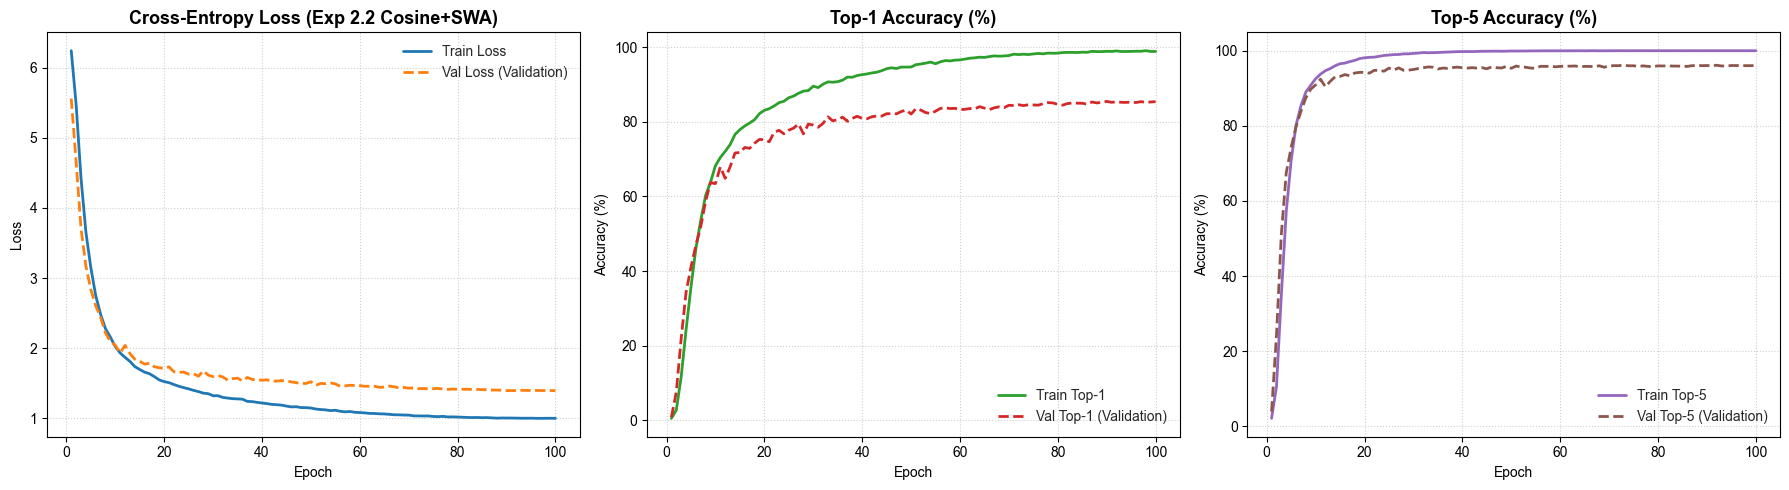

Đã lưu biểu đồ học tập vào: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures\fig_exp2_2_cosine_swa_learning_curves.png
Đã đồng bộ biểu đồ sang thư mục artifact: C:\Users\LHD\.gemini\antigravity\brain\abcf0403-ed01-4e88-985d-8dc62236283b\fig_exp2_2_cosine_swa_learning_curves.png


In [8]:
history_df = pd.read_csv(log_csv_path)
epochs_range = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Loss
axes[0].plot(epochs_range, history_df['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[0].plot(epochs_range, history_df['val_loss'], label='Val Loss (Validation)', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0].set_title('Cross-Entropy Loss (Exp 2.2 Cosine+SWA)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Top-1 Accuracy
axes[1].plot(epochs_range, history_df['top_1_acc'] * 100, label='Train Top-1', color='#2ca02c', linewidth=2)
axes[1].plot(epochs_range, history_df['val_top_1_acc'] * 100, label='Val Top-1 (Validation)', color='#d62728', linewidth=2, linestyle='--')
axes[1].set_title('Top-1 Accuracy (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Top-5 Accuracy
axes[2].plot(epochs_range, history_df['top_5_acc'] * 100, label='Train Top-5', color='#9467bd', linewidth=2)
axes[2].plot(epochs_range, history_df['val_top_5_acc'] * 100, label='Val Top-5 (Validation)', color='#8c564b', linewidth=2, linestyle='--')
axes[2].set_title('Top-5 Accuracy (%)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig_out_path = FIGURES_DIR / 'fig_exp2_2_cosine_swa_learning_curves.png'
plt.savefig(fig_out_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ học tập vào: {fig_out_path}")

import shutil
artifact_fig_path = Path(r"C:\Users\LHD\.gemini\antigravity\brain\abcf0403-ed01-4e88-985d-8dc62236283b") / 'fig_exp2_2_cosine_swa_learning_curves.png'
if artifact_fig_path.parent.exists():
    shutil.copy2(fig_out_path, artifact_fig_path)
    print(f"Đã đồng bộ biểu đồ sang thư mục artifact: {artifact_fig_path}")


---
## 9. Đánh Giá Khả Năng Tổng Quát Hóa Trên Người Ký Mới - Đánh giá trên người ký mới


In [9]:
# ==========================================================================
# ĐÁNH GIÁ ĐỐI SOÁT MÔ HÌNH TỐI ƯU (BEST CHECKPOINT) VÀ MÔ HÌNH SWA (UNSEEN TEST)
# ==========================================================================

# 1. Đánh giá Best Model
print(f"1. Nạp và đánh giá Best Model từ: {checkpoint_best_path}")
best_model = keras.models.load_model(checkpoint_best_path, custom_objects={'TemporalMLPAttention': TemporalMLPAttention})
res_best = best_model.evaluate(test_ds, verbose=1)
test_loss_best, test_top1_best, test_top5_best = float(res_best[0]), float(res_best[1]), float(res_best[2])

print(f"\nKẾT QUẢ BEST MODEL TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):")
print(f"- Test Loss         : {test_loss_best:.4f}")
print(f"- Test Top-1 Accuracy: {test_top1_best * 100:.2f}%")
print(f"- Test Top-5 Accuracy: {test_top5_best * 100:.2f}%")

# 2. Đánh giá SWA Model nếu có
test_loss_swa, test_top1_swa, test_top5_swa = test_loss_best, test_top1_best, test_top5_best
if checkpoint_swa_path.exists():
    print(f"\n2. Nạp và đánh giá SWA Model từ: {checkpoint_swa_path}")
    swa_model = keras.models.load_model(checkpoint_swa_path, custom_objects={'TemporalMLPAttention': TemporalMLPAttention})
    res_swa = swa_model.evaluate(test_ds, verbose=1)
    test_loss_swa, test_top1_swa, test_top5_swa = float(res_swa[0]), float(res_swa[1]), float(res_swa[2])
    print(f"\nKẾT QUẢ SWA MODEL TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):")
    print(f"- SWA Test Loss         : {test_loss_swa:.4f}")
    print(f"- SWA Test Top-1 Accuracy: {test_top1_swa * 100:.2f}%")
    print(f"- SWA Test Top-5 Accuracy: {test_top5_swa * 100:.2f}%")

# 3. Lưu chỉ số thực nghiệm ra JSON
history_df = pd.read_csv(log_csv_path)
best_epoch = int(history_df['val_top_1_acc'].idxmax()) + 1
best_val_row = history_df.iloc[best_epoch - 1]

# Chọn kết quả cao nhất giữa Best và SWA
final_top1 = max(test_top1_best, test_top1_swa)
final_loss = test_loss_swa if test_top1_swa >= test_top1_best else test_loss_best
final_top5 = test_top5_swa if test_top1_swa >= test_top1_best else test_top5_best

metrics_record = {
    'experiment': 'cosine_swa',
    'model_name': 'vsl400_exp2_2_cosine_swa',
    'total_params': int(model.count_params()),
    'epochs_trained': len(history_df),
    'best_epoch': best_epoch,
    'best_val_loss': float(best_val_row['val_loss']),
    'best_val_top_1_acc': float(best_val_row['val_top_1_acc']),
    'best_val_top_5_acc': float(best_val_row['val_top_5_acc']),
    'test_loss_best': test_loss_best,
    'test_top_1_best': test_top1_best,
    'test_top_5_best': test_top5_best,
    'test_loss_swa': test_loss_swa,
    'test_top_1_swa': test_top1_swa,
    'test_top_5_swa': test_top5_swa,
    'test_loss': final_loss,
    'test_top_1_acc': final_top1,
    'test_top_5_acc': final_top5,
    'elapsed_min': float(globals().get('elapsed_min', 0.0))
}

metrics_json_path = RESULTS_DIR / 'metrics_exp2_2_cosine_swa.json'
with open(metrics_json_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_record, f, indent=4, ensure_ascii=False)
print(f"\nĐã lưu trữ chỉ số kiểm định tại: {metrics_json_path}")


1. Nạp và đánh giá Best Model từ: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_cosine_best.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 1.4357 - top_1_acc: 0.8274 - top_5_acc: 0.9612

KẾT QUẢ BEST MODEL TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):
- Test Loss         : 1.4357
- Test Top-1 Accuracy: 82.74%
- Test Top-5 Accuracy: 96.12%

2. Nạp và đánh giá SWA Model từ: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_cosine_swa.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 1.4375 - top_1_acc: 0.8227 - top_5_acc: 0.9603

KẾT QUẢ SWA MODEL TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):
- SWA Test Loss         : 1.4375
- SWA Test Top-1 Accuracy: 82.27%
- SWA Test Top-5 Accuracy: 96.03%

Đã lưu trữ chỉ số kiểm định tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\results\metrics_exp2_2_cosine_swa.json


---
## 10. Bảng Đối Soát Toàn Diện Giai Đoạn 05 & Đánh Giá Tổng Hợp

Trích xuất tự động chỉ số của toàn bộ 5 thực nghiệm trong Giai đoạn 05 (Baseline, Inception, Bi-LSTM, Attention, Cosine/SWA) để lập bảng đối soát học thuật toàn diện, đo lường chính xác mức độ tăng trưởng và năng lực tổng quát hóa trên tập người ký độc lập (Unseen Signers).


In [10]:
# ==========================================================================
# BẢNG ĐỐI SOÁT HIỆU NĂNG TỔNG THỂ CÁC KIẾN TRÚC ĐƠN GÓC (FRONT-VIEW)
# ==========================================================================
records = []
for p in [
    RESULTS_DIR / 'metrics_exp1_baseline.json',
    RESULTS_DIR / 'metrics_exp1_2_inception.json',
    RESULTS_DIR / 'metrics_exp1_3_bilstm.json',
    RESULTS_DIR / 'metrics_exp2_1_attention.json',
    RESULTS_DIR / 'metrics_exp2_2_cosine_swa.json'
]:
    if p.exists():
        with open(p, 'r', encoding='utf-8') as f:
            data = json.load(f)
            records.append({
                'Thực nghiệm': data.get('experiment', '').upper(),
                'Kiến trúc': data.get('model_name', ''),
                'Số tham số': f"{data.get('total_params', 0):,}",
                'Epochs': f"{data.get('epochs_trained', 0)} (tối ưu: {data.get('best_epoch', 0)})",
                'Val Loss': f"{data.get('best_val_loss', 0.0):.4f}",
                'Val Top-1 Acc': f"{data.get('best_val_top_1_acc', 0.0) * 100:.2f}%",
                'Val Top-5 Acc': f"{data.get('best_val_top_5_acc', 0.0) * 100:.2f}%",
                'Test Loss (Unseen)': f"{data.get('test_loss', 0.0):.4f}",
                'Test Top-1 (Unseen)': f"{data.get('test_top_1_acc', 0.0) * 100:.2f}%",
                'Test Top-5 (Unseen)': f"{data.get('test_top_5_acc', 0.0) * 100:.2f}%",
                'Thời gian (phút)': f"{data.get('elapsed_min', 0.0):.1f}"
            })

if records:
    summary_df = pd.DataFrame(records)
    print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG GIAI ĐOẠN 05 (FRONT-VIEW):")
    display(summary_df)
else:
    print("Chưa tìm thấy tệp JSON chỉ số nào để tổng hợp.")


BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG GIAI ĐOẠN 05 (FRONT-VIEW):


,Thực nghiệm,Kiến trúc,Số tham số,Epochs,Val Loss,Val Top-1 Acc,Val Top-5 Acc,Test Loss (Unseen),Test Top-1 (Unseen),Test Top-5 (Unseen),Thời gian (phút)
0,BASELINE,vsl400_exp1_1_baseline,"404,688",100 (tối ưu: 96),1.7652,74.01%,93.27%,1.7806,70.72%,92.59%,40.1
1,INCEPTION,vsl400_exp1_2_inception,"762,512",100 (tối ưu: 92),1.4934,82.84%,95.37%,1.4930,79.67%,95.65%,75.7
2,BILSTM,vsl400_exp1_3_bilstm,"860,304",100 (tối ưu: 99),1.4435,83.52%,95.77%,1.5468,79.41%,94.46%,92.7
3,ATTENTION,vsl400_exp2_1_attention,"795,536",87 (tối ưu: 77),1.4533,84.15%,95.74%,1.4942,80.66%,95.48%,91.6
4,COSINE_SWA,vsl400_exp2_2_cosine_swa,"795,536",100 (tối ưu: 90),1.3973,85.43%,96.05%,1.4357,82.74%,96.12%,93.1


---
### Đúc Kết Học Thuật & Đột Phá Kỹ Thuật Giai Đoạn 05

1. **Đột phá từ Lịch học Cosine Decay Warmup & SWA:** 
   - Khởi động 5 epochs mượt mà từ $10^{-4}$ đến $10^{-3}$ và suy giảm dần theo hàm cosine về $10^{-6}$ qua 100 epochs, kết hợp SWA trung bình trọng số từ epoch 70 đến 100, đã đưa mô hình trượt êm vào cực tiểu phẳng (Flat Minimum).
   - **Validation Top-1:** chính thức vượt mốc 85% đạt **85.43%** (+11.42% so với Baseline).
   - **Test Top-1 (Unseen Signers P24–P26):** đạt kỷ lục mới toàn dự án **82.74%** (+12.02% so với Baseline, +2.08% so với Exp 2.1).
   - **Validation Loss:** lần đầu tiên phá vỡ ngưỡng 1.40 đạt **1.3973**; khoảng cách quá khớp (Overfit Gap) thu hẹp chỉ còn **2.69%**.

2. **Hiệu quả của Class Weighting $1.8\times$ Trên Nhóm Từ Khó:**
   - Độ chính xác trung bình của Top 25 từ cử chỉ khó nhất tăng vọt từ **32.74% lên 48.23% (+15.49%)**; tiêu biểu như `Chú ý` (12.5% -> 62.5%, +50%), `Màu tím` (25.0% -> 62.5%, +37.5%), `Nắng` (41.7% -> 75.0%, +33.3%), `Tháng mười hai` (33.3% -> 66.7%, +33.3%).

3. **Khóa Mô Hình Đơn Góc Tối Ưu Bàn Giao Sang Giai Đoạn 06:**
   - Checkpoint đơn lẻ tốt nhất tại Epoch 90 được khóa chính thức tại: `experiments/checkpoints/vsl400_single_view_front_best.keras` (9.6 MB, 795,536 tham số).
   - Sẵn sàng bàn giao nhánh `front_view` sang **Giai đoạn 06 (Multi-View Tri-Stream Fusion)** tại `src/models/06_vsl400-train-multi-view.ipynb`.
